# 02 — Results: what each retrieval layer buys, and what it costs

Reads the per-query results written by `make b2` (`results/per_query_*.parquet`) and the
aggregates of `make b2-report` (`results/summary.csv`, `results/paired_tests.csv`).
Every number below comes from those files. The protocol was frozen before they existed.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

R = Path("../results")
summary = pd.read_csv(R / "summary.csv")
tests = pd.read_csv(R / "paired_tests.csv")
per_query = pd.concat([pd.read_parquet(p) for p in sorted(R.glob("per_query_*.parquet"))])
ORDER = ["bm25", "dense", "hybrid", "hybrid_rerank", "contextual_bm25", "contextual_dense",
         "contextual_hybrid", "contextual_hybrid_rerank"]
summary["config"] = pd.Categorical(summary["config"], [c for c in ORDER if c in set(summary.config)], ordered=True)
print(per_query.groupby(["strategy", "setting", "config"]).size().unstack("config").iloc[:, :4])

config                      bm25  contextual_bm25  contextual_dense  \
strategy    setting                                                   
naive       company_filter  1147             1147              1147   
            main            1147             1147              1147   
            raw_question    1147             1147              1147   
table_aware company_filter  1147             1147              1147   
            main            1147             1147              1147   
            raw_question    1147             1147              1147   

config                      contextual_hybrid  
strategy    setting                            
naive       company_filter               1147  
            main                         1147  
            raw_question                 1147  
table_aware company_filter               1147  
            main                         1147  
            raw_question                 1147  


## 1. The main table (company-prefixed queries)

`pass_all@k`: share of the 1,147 questions whose **every** gold fact is in the top-k. Brackets are
95 % bootstrap intervals.

In [2]:
def fmt(row, m):
    return f"{row[m]:.3f} [{row[m + '_lo']:.3f}, {row[m + '_hi']:.3f}]"

main = summary[summary.setting == "main"].sort_values(["strategy", "config"])
table = pd.DataFrame({
    "strategy": main.strategy, "config": main.config,
    "pass_all@5": [fmt(r, "pass_all@5") for _, r in main.iterrows()],
    "pass_all@10": [fmt(r, "pass_all@10") for _, r in main.iterrows()],
    "pass_all@20": [fmt(r, "pass_all@20") for _, r in main.iterrows()],
    "pass_any@10": main["pass_any@10"].round(3),
    "mrr@10": main["mrr@10"].round(3),
    "p50 ms": main.latency_p50_ms.round(1), "p95 ms": main.latency_p95_ms.round(1),
})
table.reset_index(drop=True)

,strategy,config,pass_all@5,pass_all@10,pass_all@20,pass_any@10,mrr@10,p50 ms,p95 ms
0,naive,bm25,"0.664 [0.637, 0.691]","0.735 [0.709, 0.760]","0.793 [0.769, 0.815]",0.840,0.611,4.0,5.7
1,naive,dense,"0.598 [0.569, 0.626]","0.674 [0.646, 0.701]","0.747 [0.721, 0.772]",0.778,0.548,6.4,9.7
2,naive,hybrid,"0.649 [0.621, 0.676]","0.726 [0.700, 0.752]","0.803 [0.779, 0.826]",0.833,0.605,9.3,14.4
3,naive,hybrid_rerank,"0.779 [0.756, 0.803]","0.840 [0.818, 0.860]","0.878 [0.858, 0.896]",0.922,0.752,354.6,395.8
4,naive,contextual_bm25,"0.804 [0.780, 0.827]","0.874 [0.854, 0.893]","0.932 [0.917, 0.946]",0.936,0.722,4.4,6.3
5,naive,contextual_dense,"0.762 [0.737, 0.786]","0.853 [0.831, 0.873]","0.907 [0.889, 0.923]",0.901,0.664,6.0,9.4
6,naive,contextual_hybrid,"0.828 [0.806, 0.849]","0.892 [0.874, 0.909]","0.938 [0.924, 0.951]",0.937,0.712,9.1,14.6
7,naive,contextual_hybrid_rerank,"0.900 [0.882, 0.917]","0.944 [0.930, 0.957]","0.968 [0.957, 0.977]",0.984,0.827,445.9,495.1
8,table_aware,bm25,"0.412 [0.383, 0.440]","0.480 [0.452, 0.509]","0.556 [0.527, 0.585]",0.685,0.458,6.2,8.6
9,table_aware,dense,"0.428 [0.400, 0.456]","0.516 [0.486, 0.545]","0.590 [0.561, 0.618]",0.732,0.479,6.4,9.9


## 2. Fair comparison of chunkings: equal token budget

In [3]:
budget = main.pivot_table(index="config", columns="strategy",
                          values=["pass_all@10", "pass_all@1000tok", "pass_all@2000tok"], observed=True)
budget.round(3)

pass_all@10             pass_all@1000tok              \
strategy                       naive table_aware            naive table_aware   
config                                                                          
bm25                           0.735       0.480            0.664       0.463   
dense                          0.674       0.516            0.601       0.516   
hybrid                         0.726       0.542            0.649       0.530   
hybrid_rerank                  0.840       0.605            0.782       0.606   
contextual_bm25                0.874       0.734            0.759       0.685   
contextual_dense               0.853       0.783            0.697       0.758   
contextual_hybrid              0.892       0.790            0.767       0.765   
contextual_hybrid_rerank       0.944       0.811            0.853       0.756   

                         pass_all@2000tok              
strategy                            naive table_aware  
config                                                 
bm25                                0.735       0.535  
dense                               0.674       0.591  
hybrid                              0.728       0.590  
hybrid_rerank                       0.840       0.657  
contextual_bm25                     0.857       0.776  
contextual_dense                    0.823       0.844  
contextual_hybrid                   0.870       0.840  
contextual_hybrid_rerank            0.926       0.848

## 3. Paired tests (McNemar exact, Holm-adjusted)

`a_only`: queries where the first system succeeds and the second fails; `b_only`: the reverse.
Only these discordant queries carry evidence.

In [4]:
tests.round(4)

,comparison,delta_pass_all@10,a_only,b_only,p_value,p_holm,significant
0,naive: dense -> hybrid,0.0523,36,96,0.0000,0.0000,True
1,naive: hybrid -> hybrid_rerank,0.1133,11,141,0.0000,0.0000,True
2,naive: hybrid_rerank -> contextual_hybrid_rerank,0.1046,11,131,0.0000,0.0000,True
3,table_aware: dense -> hybrid,0.0262,34,64,0.0032,0.0032,True
4,table_aware: hybrid -> hybrid_rerank,0.0628,28,100,0.0000,0.0000,True
5,table_aware: hybrid_rerank -> contextual_hybri...,0.2058,23,259,0.0000,0.0000,True
6,dense: naive -> table_aware,-0.1578,306,125,0.0000,0.0000,True
7,hybrid: naive -> table_aware,-0.1840,298,87,0.0000,0.0000,True
8,hybrid_rerank: naive -> table_aware,-0.2345,320,51,0.0000,0.0000,True
9,contextual_hybrid_rerank: naive -> table_aware,-0.1334,176,23,0.0000,0.0000,True


## 4. Precision vs latency

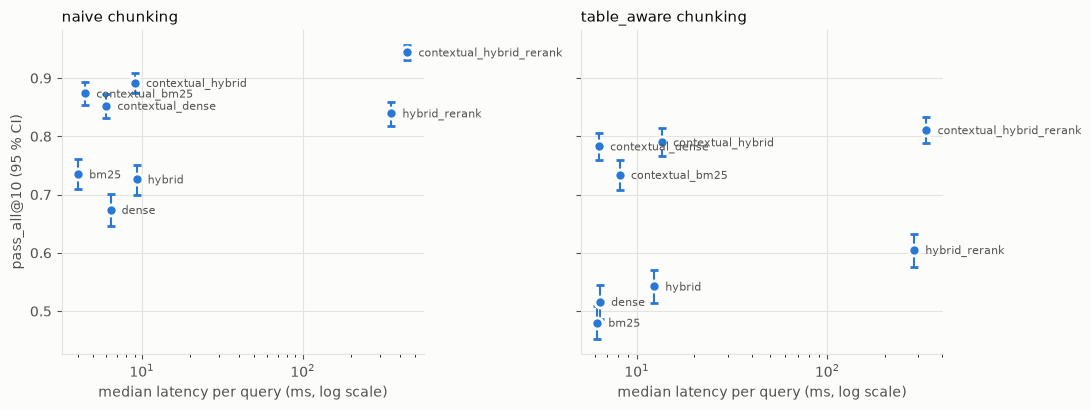

In [5]:
SERIES, INK, INK2, GRID, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True, facecolor=SURFACE)
for ax, (strategy, g) in zip(axes, main.groupby("strategy", observed=True)):
    ax.set_facecolor(SURFACE)
    for _, r in g.iterrows():
        lo, hi = r["pass_all@10"] - r["pass_all@10_lo"], r["pass_all@10_hi"] - r["pass_all@10"]
        ax.errorbar(r.latency_p50_ms, r["pass_all@10"], yerr=[[lo], [hi]], fmt="o", ms=8,
                    color=SERIES, ecolor=SERIES, elinewidth=1.5, capsize=3, mec=SURFACE, mew=2)
        ax.annotate(str(r.config), (r.latency_p50_ms, r["pass_all@10"]), textcoords="offset points",
                    xytext=(8, -3), fontsize=8, color=INK2)
    ax.set_xscale("log")
    ax.set_title(f"{strategy} chunking", color=INK, fontsize=11, loc="left")
    ax.set_xlabel("median latency per query (ms, log scale)", color=INK2)
    ax.grid(color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK2)
axes[0].set_ylabel("pass_all@10 (95 % CI)", color=INK2)
plt.tight_layout(); plt.show()

## 5. Query form: raw question vs company prefix vs company filter

In [6]:
settings = summary.pivot_table(index=["strategy", "config"], columns="setting",
                               values="pass_all@10", observed=True)
settings[["raw_question", "main", "company_filter"]].round(3)

setting                               raw_question   main  company_filter
strategy    config                                                       
naive       bm25                             0.695  0.735           0.898
            dense                            0.609  0.674           0.876
            hybrid                           0.684  0.726           0.910
            hybrid_rerank                    0.813  0.840           0.935
            contextual_bm25                  0.770  0.874           0.949
            contextual_dense                 0.645  0.853           0.908
            contextual_hybrid                0.769  0.892           0.942
            contextual_hybrid_rerank         0.873  0.944           0.970
table_aware bm25                             0.485  0.480           0.691
            dense                            0.530  0.516           0.724
            hybrid                           0.555  0.542           0.725
            hybrid_rerank                    0.616  0.605           0.761
            contextual_bm25                  0.616  0.734           0.823
            contextual_dense                 0.644  0.783           0.825
            contextual_hybrid                0.673  0.790           0.840
            contextual_hybrid_rerank         0.717  0.811           0.851